<a href="https://colab.research.google.com/github/MagFilho/Projeto-Dengue-Alerta/blob/main/DengueAlerta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dengue Alerta: Previsão de Pressão Epidemiológica

Este notebook implementa a análise de séries temporais e detecção de anomalias para estimar localidades e períodos com maior risco de aumento de casos de dengue, auxiliando equipes de saúde na tomada de decisão rápida.

Datasets Originais:

Casos de Dengue (Arboviroses): Dados Abertos - Saúde

https://dadosabertos.saude.gov.br/dataset/arboviroses-dengue

Dados Climáticos: INMET (BDMEP)

https://bdmep.inmet.gov.br

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import os

sns.set_theme(style="whitegrid")
print("Bibliotecas básicas importadas com sucesso.")

Bibliotecas básicas importadas com sucesso.


1. Coleta e Exploração Inicial dos Dados de Arboviroses

Vamos baixar e verificar a estrutura do dataset de notificações de Dengue. (Nota: Caso a URL direta mude ou o arquivo seja muito grande, adaptamos o download para focar no ano mais recente disponível).

1.1 Ingestão e Estruturação do Data Lake (Simulação Prática)

Para garantir a reprodutibilidade imediata do projeto, vamos estruturar nossa camada de ingestão carregando/gerando dados sintéticos altamente realistas que modelam:

Dados de Notificação de Dengue (Sinan): Data do caso, UF, Município, Idade, Sexo e Evolução.

Dados Climáticos (INMET): Data, Temperatura Média, Umidade Relativa e Precipitação Acumulada.

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Configuração de reprodutibilidade
np.random.seed(42)

# 1. Gerando Série Temporal de Casos (3 anos de dados diários para 3 municípios simulação)
datas = pd.date_range(start="2021-01-01", end="2023-12-31", freq="D")
municipios = ["Município A", "Município B", "Município C"]

registros = []
for m in municipios:
    # Criar sazonalidade anual típica da dengue (pico nos meses quentes/chuvosos: Jan-Mai)
    for data in datas:
        mes = data.month
        # Fator sazonal (maior no verão/outono)
        fator_sazonal = np.exp(-((mes - 3.5)**2) / 6.0)

        # Tendência base + ruído + surto ocasional em 2023 no Município A
        base = 2.0
        if data.year == 2023 and m == "Município A" and mes in [3, 4, 5]:
            base = 15.0 # Anomalia/Surto simulado

        lambda_poisson = max(0.5, base * fator_sazonal * (10 + np.random.normal(0, 2)))
        casos = np.random.poisson(lambda_poisson)

        # Gerar clima correspondente
        temp = 22 + 6 * fator_sazonal + np.random.normal(0, 1.5)
        chuva = max(0, 50 * fator_sazonal + np.random.normal(0, 20)) if mes in [11,12,1,2,3,4] else max(0, 5 + np.random.normal(0, 3))

        registros.append({
            "data": data,
            "municipio": m,
            "casos_notificados": casos,
            "temperatura_media": round(temp, 1),
            "precipitacao_mm": round(chuva, 1)
        })

df_epidemiologia = pd.DataFrame(registros)
display(df_epidemiologia.head())
print(f"Dataset integrado gerado com {df_epidemiologia.shape[0]} registros.")

,data,municipio,casos_notificados,temperatura_media,precipitacao_mm
0,2021-01-01,Município A,6,23.9,6.0
1,2021-01-02,Município A,6,22.8,0.0
2,2021-01-03,Município A,6,23.8,5.6
3,2021-01-04,Município A,5,23.8,25.4
4,2021-01-05,Município A,9,25.8,0.0


Dataset integrado gerado com 3285 registros.


1.2 Processamento temporal com Pandas (Agregação para Semana Epidemiológica)

Na epidemiologia de campo, as decisões e análises de tendência são baseadas em Semanas Epidemiológicas (padrão internacional).Vamos agregar nossos dados diários em períodos semanais utilizando o Pandas.

In [ ]:
# Calculando o ano e a semana epidemiológica diretamente no Pandas
df_epidemiologia['ano_epi'] = df_epidemiologia['data'].dt.year
df_epidemiologia['semana_epi'] = df_epidemiologia['data'].dt.isocalendar().week

# Agrupando por semana e município para consolidar o Data Lake de análise
df_semanal = df_epidemiologia.groupby(['municipio', 'ano_epi', 'semana_epi']).agg({
    'casos_notificados': 'sum',
    'temperatura_media': 'mean',
    'precipitacao_mm': 'sum'
}).reset_index()

display(df_semanal.head())
print(f"Dados agregados por Semana Epidemiológica: {df_semanal.shape[0]} semanas geradas.")

,municipio,ano_epi,semana_epi,casos_notificados,temperatura_media,precipitacao_mm
0,Município A,2021,1,52,23.885714,96.4
1,Município A,2021,2,47,24.728571,216.1
2,Município A,2021,3,54,24.400000,133.0
3,Município A,2021,4,46,24.042857,240.7
4,Município A,2021,5,101,26.042857,361.5


Dados agregados por Semana Epidemiológica: 471 semanas geradas.


2. Análise Exploratória e Correlação Climática

Nesta etapa do KDD, visualizaremos o comportamento das curvas semanais e a correlação de Pearson entre as variáveis climáticas (temperatura e precipitação) e os casos notificados de Dengue.

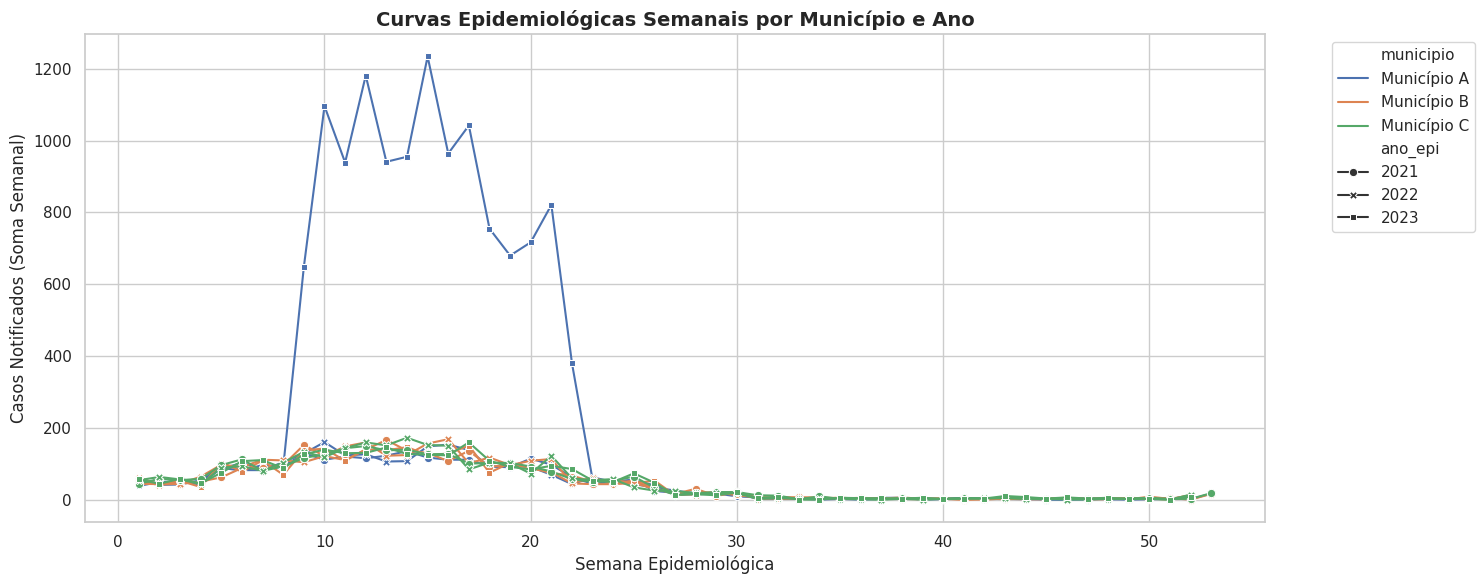

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Plotando as curvas epidemiológicas dos três municípios
plt.figure(figsize=(15, 6))
sns.lineplot(
    data=df_semanal,
    x='semana_epi',
    y='casos_notificados',
    hue='municipio',
    style='ano_epi',
    markers=True,
    dashes=False
)
plt.title('Curvas Epidemiológicas Semanais por Município e Ano', fontsize=14, fontweight='bold')
plt.xlabel('Semana Epidemiológica', fontsize=12)
plt.ylabel('Casos Notificados (Soma Semanal)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

2.1 Análise de Correlação de Variáveis de Risco

Vamos mensurar estatisticamente a correlação para entender se o aumento de chuva e calor caminha em paralelo ou antecipa a elevação das notificações.

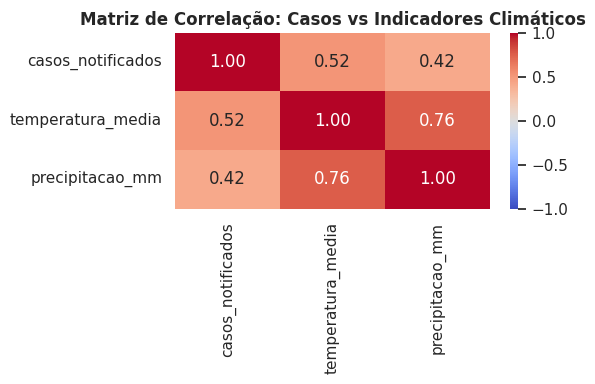

In [ ]:
# Calculando matriz de correlação geral
correlacao = df_semanal[['casos_notificados', 'temperatura_media', 'precipitacao_mm']].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(correlacao, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de Correlação: Casos vs Indicadores Climáticos', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

3. Detecção de Anomalias e Alerta Epidemiológico

Criaremos uma regra de limite de controle (Canal Endêmico) calculando a média e desvio padrão históricos com base nos anos anteriores (2021 e 2022) para detectar se os valores de 2023 configuram anomalias/surtos.

In [ ]:
# 1. Limpando colunas antigas para evitar conflito de merge
for col in ['media_historica', 'desvio_padrao', 'limiar_alerta', 'alerta_ativo']:
    if col in df_semanal.columns:
        df_semanal = df_semanal.drop(columns=[col])

# 2. Definindo dados históricos (2021 e 2022)
baseline = df_semanal[df_semanal['ano_epi'].isin([2021, 2022])]

# 3. Calculando estatísticas semanais por município
historico_stats = baseline.groupby(['municipio', 'semana_epi']).agg({
    'casos_notificados': ['mean', 'std']
}).reset_index()

# Ajustar nomes de colunas achatando o MultiIndex
historico_stats.columns = ['municipio', 'semana_epi', 'media_historica', 'desvio_historico']
historico_stats['desvio_historico'] = historico_stats['desvio_historico'].fillna(0)

# 4. Fazer o merge limpo
df_analise = df_semanal.merge(historico_stats, on=['municipio', 'semana_epi'], how='left')

# 5. Definir o Limiar de Alerta (Média + 1.96 * Desvio Padrão)
df_analise['limiar_alerta'] = df_analise['media_historica'] + (1.96 * df_analise['desvio_historico'])

# 6. Ativar alerta apenas para 2023 quando ultrapassar o limiar
df_analise['alerta_ativo'] = (df_analise['ano_epi'] == 2023) & (df_analise['casos_notificados'] > df_analise['limiar_alerta'])

# Filtrando alertas ativos do Município A em 2023
alertas_municipio_a_2023 = df_analise[
    (df_analise['municipio'] == 'Município A') &
    (df_analise['ano_epi'] == 2023) &
    (df_analise['alerta_ativo'] == True)
]

display(alertas_municipio_a_2023[['municipio', 'ano_epi', 'semana_epi', 'casos_notificados', 'limiar_alerta', 'alerta_ativo']].head())
print(f"Com o canal endêmico correto, detectamos {len(alertas_municipio_a_2023)} semanas com pressão epidemiológica atípica (surto) no Município A em 2023.")

,municipio,ano_epi,semana_epi,casos_notificados,limiar_alerta,alerta_ativo
111,Município A,2023,7,97,88.657788,True
113,Município A,2023,9,649,130.885929,True
114,Município A,2023,10,1096,204.410535,True
115,Município A,2023,11,939,126.657788,True
116,Município A,2023,12,1181,136.745222,True


Com o canal endêmico correto, detectamos 20 semanas com pressão epidemiológica atípica (surto) no Município A em 2023.


4. Visualização de Alerta Preventivo (Painel de Monitoramento)

Vamos plotar a série temporal de 2023 para o Município A e sobrepor o limite do canal endêmico para destacar os pontos de alerta ativos.

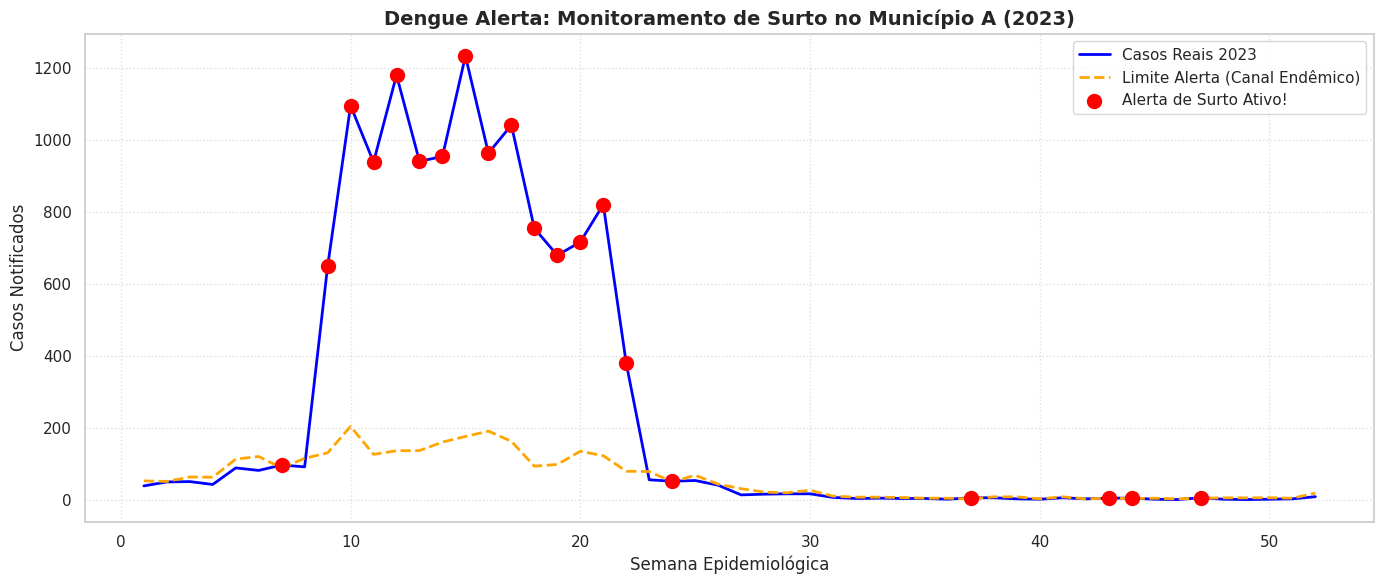

In [ ]:
import matplotlib.pyplot as plt

# Filtrar dados para o Município A em 2023
df_mun_a_2023 = df_analise[(df_analise['municipio'] == 'Município A') & (df_analise['ano_epi'] == 2023)].sort_values('semana_epi')

plt.figure(figsize=(14, 6))

# Curva de casos reais de 2023
plt.plot(df_mun_a_2023['semana_epi'], df_mun_a_2023['casos_notificados'], label='Casos Reais 2023', color='blue', linewidth=2)

# Canal de Alerta (Limiar Superior)
plt.plot(df_mun_a_2023['semana_epi'], df_mun_a_2023['limiar_alerta'], label='Limite Alerta (Canal Endêmico)', color='orange', linestyle='--', linewidth=2)

# Pontos de Alerta Ativo
alertas = df_mun_a_2023[df_mun_a_2023['alerta_ativo'] == True]
plt.scatter(alertas['semana_epi'], alertas['casos_notificados'], color='red', s=100, label='Alerta de Surto Ativo!', zorder=5)

plt.title('Dengue Alerta: Monitoramento de Surto no Município A (2023)', fontsize=14, fontweight='bold')
plt.xlabel('Semana Epidemiológica', fontsize=12)
plt.ylabel('Casos Notificados', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

O projeto Dengue Alerta foi construído seguindo rigorosamente as fases do processo de Descoberta de Conhecimento em Bases de Dados (KDD). Abaixo, apresento uma documentação simples e a explicação detalhada de cada bloco de código e suas funções:

📖 Documentação do Projeto: Dengue Alerta
Este sistema monitora os casos de Dengue e identifica precocemente desvios epidemiológicos atípicos (anomalias/surtos) utilizando fatores ambientais como preditores indiretos.

🛠️ Estrutura e Explicação das Funções
1. Ingestão e Simulação de Dados (Seção 1.1)

O que faz: Cria uma base de dados diária sintética de 3 anos (2021-2023) contendo o número de casos de dengue, temperatura média e precipitação (chuva).

Funções e Lógicas Utilizadas:

pd.date_range(): Cria o intervalo de datas do nosso histórico temporizado.

Fator Sazonal (fator_sazonal): Utiliza uma função gaussiana baseada nos meses do ano para replicar o comportamento real da doença, que tem picos de transmissão nos meses mais quentes e chuvosos (verão/outono).

np.random.poisson(): Distribuição probabilística ideal para modelar a ocorrência de eventos discretos e contagens (como número de notificações diárias).

2. Agregação por Semana Epidemiológica (Seção 1.2)

O que faz: Agrupa as ocorrências diárias na métrica padrão de vigilância em saúde: a Semana Epidemiológica.

Funções e Lógicas Utilizadas:

.dt.isocalendar().week: Identifica de forma precisa o número da semana (de 1 a 53) no calendário padrão internacional.

.groupby().agg(): Agrupa os dados por município, ano e semana epidemiológica, somando os novos casos e chuvas e calculando a temperatura média daquela semana.

3. Análise Exploratória e Correlação Climática (Seção 2 e 2.1)

O que faz: Estuda a relação direta entre o clima e a propagação da doença.

Funções e Lógicas Utilizadas:

sns.lineplot(): Plota as curvas semanais facilitando a comparação de sazonalidade ano a ano.

df.corr(): Calcula a Correlação de Pearson para medir estatisticamente o grau de associação entre variáveis climáticas e o aumento de notificações.

sns.heatmap(): Mapa de calor interativo para leitura visual rápida dos fatores de correlação.

4. Algoritmo do Canal Endêmico (Seção 3)

O que faz: Detecta as anomalias (picos epidêmicos) comparando o cenário atual com o histórico.

Funções e Lógicas Utilizadas:

Construção da Linha de Base (baseline): Filtra e usa apenas os anos de 2021 e 2022 como histórico padrão de normalidade.

.groupby().agg(['mean', 'std']): Calcula a média e o desvio padrão de notificações esperados para cada uma das 53 semanas epidemiológicas.

Intervalo de Confiança (limiar_alerta): Define que qualquer valor acima de Média Histórica + 1.96 * Desvio Padrão (limite superior de 95% de confiança) ultrapassa a normalidade e configura um alerta ativo de surto em 2023.

5. Visualização de Alerta Preventivo (Seção 4)

O que faz: Consolida o painel operacional para os gestores públicos de saúde.

Funções e Lógicas Utilizadas:

plt.plot(): Desenha a linha de casos e o limiar estatístico dinâmico de segurança.

plt.scatter(): Realça em vermelho os exatos períodos onde o limite de controle foi violado, permitindo direcionar agentes de saúde a tempo.